# EDA Part C: Stream Overview and Temporal Behavior

**Question:** How do fraudulent and normal users differ in *when* and *how fast* they message the bank's chatbot?

Data: the simulated OLTP message stream (`data/simulated/messages/`) and user table (`data/simulated/users.parquet`).
All aggregation runs in **PySpark**. Locally it uses `local[*]`; on the EC2 cluster, change `DATA_ROOT` to the
`s3a://` path and `MASTER` to the cluster URL. Only the small aggregated results are brought back to pandas for plotting.

> **Note on interpretation.** `is_fraud` and `fraud_pattern` come from the simulation rules, not from investigators.
> These figures check that the stream reflects the fraud schemes we designed. They are not findings about real fraudsters.

| Figure | Content |
|---|---|
| C1 | Stream overview: users, messages, fraud shares, daily volume and fraud rate, label coverage |
| C2 | Hour-of-day × day-of-week activity, normal vs fraud messages |
| C3 | Time between consecutive messages from the same user (log scale) |
| C4 | Session size and duration, ordinary sessions vs fraud bursts |

In [1]:
import time
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F

# ---- Settings: the only lines to change on the cluster ----
MASTER = "local[*]"                       # e.g. "spark://<master-private-ip>:7077" on EC2
# Repo root: works whether the notebook is in the repo root or in eda/
ROOT = Path.cwd().parent if Path.cwd().name == "eda" else Path.cwd()
DATA_ROOT = (ROOT / "data").as_posix()    # e.g. "s3a://<public-bucket>/banking77" on the cluster

FIG_DIR = ROOT / "figures"
OUT_DIR = ROOT / "eda" / "output"
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

spark = (
    SparkSession.builder.master(MASTER)
    .appName("banking77-eda-C")
    .config("spark.sql.session.timeZone", "UTC")   # received_ts is the user's local clock; keep Spark from shifting it
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")

PATTERNS = ["account_takeover", "money_mule", "card_testing", "location_anomaly", "night_activity"]
COLORS = {
    "normal": "#7f8c8d",
    "account_takeover": "#c0392b",
    "money_mule": "#d68910",
    "card_testing": "#8e44ad",
    "location_anomaly": "#2471a3",
    "night_activity": "#17202a",
}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

timings = {}   # wall-clock time of each Spark job, reused in the Spark 1-pager

def timed(name, fn):
    start = time.time()
    result = fn()
    timings[name] = round(time.time() - start, 2)
    print(f"{name}: {timings[name]} s")
    return result

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/26 11:15:13 WARN Utils: Your hostname, hanmingyangdeMacBook-Air-2.local, resolves to a loopback address: 127.0.0.1; using 10.0.0.95 instead (on interface en0)
26/11/26 11:15:13 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/26 11:15:13 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
msgs = spark.read.option("basePath", f"{DATA_ROOT}/simulated/messages").parquet(f"{DATA_ROOT}/simulated/messages")
users = spark.read.parquet(f"{DATA_ROOT}/simulated/users.parquet")

# Newer Spark reads received_ts as TIMESTAMP_NTZ; cast it to a plain timestamp (with the UTC session
# time zone the wall-clock values do not change) so date arithmetic works on any Spark version.
msgs = msgs.withColumn("received_ts", F.col("received_ts").cast("timestamp"))
# One label for each message: its fraud pattern, or "normal"
msgs = msgs.withColumn("group", F.coalesce(F.col("fraud_pattern"), F.lit("normal")))
msgs.cache()
print(f"partitions: {msgs.rdd.getNumPartitions()}")
msgs.printSchema()

partitions: 8
root
 |-- message_id: long (nullable = true)
 |-- received: string (nullable = true)
 |-- received_ts: timestamp (nullable = true)
 |-- text: string (nullable = true)
 |-- label: long (nullable = true)
 |-- label_source: string (nullable = true)
 |-- intent_set_version: long (nullable = true)
 |-- user_id: long (nullable = true)
 |-- session_id: long (nullable = true)
 |-- city: string (nullable = true)
 |-- lat: double (nullable = true)
 |-- lon: double (nullable = true)
 |-- is_fraud: boolean (nullable = true)
 |-- fraud_pattern: string (nullable = true)
 |-- date: date (nullable = true)
 |-- group: string (nullable = false)



## C1. Stream overview

What the simulated OLTP stream contains: how many users and messages, how fraud is spread across the five patterns,
and whether the daily fraud rate and the 30% manual-label coverage stay stable over the window.

In [3]:
overview = timed("C1 overview", lambda: msgs.agg(
    F.count("*").alias("messages"),
    F.countDistinct("user_id").alias("users"),
    F.countDistinct("session_id").alias("sessions"),
    F.round(F.avg(F.col("label").isNotNull().cast("int")), 4).alias("label_coverage"),
    F.round(F.avg(F.col("is_fraud").cast("int")), 4).alias("fraud_message_rate"),
    F.min("received_ts").alias("first_message"),
    F.max("received_ts").alias("last_message"),
).toPandas())
overview.T.rename(columns={0: "value"})

C1 overview: 8.16 s


,value
messages,500000
users,10000
sessions,147056
label_coverage,0.2999
fraud_message_rate,0.0128
first_message,2026-10-01 00:01:29
last_message,2026-10-31 23:56:43


In [4]:
# Users and messages per persona. A fraud user's background messages are ordinary, so we count
# the persona's users, all of their messages, and only the flagged burst messages separately.
persona = timed("C1 persona table", lambda: (
    users.groupBy("persona").agg(
        F.count("*").alias("users"),
        F.sum("n_messages").alias("all_messages"),
        F.sum("n_fraud_messages").alias("fraud_messages"),
    ).toPandas()
))
persona["share_of_users"] = (persona["users"] / persona["users"].sum()).round(4)
persona["share_of_fraud_messages"] = (persona["fraud_messages"] / persona["fraud_messages"].sum()).round(4)
persona["msgs_per_user"] = (persona["all_messages"] / persona["users"]).round(1)
persona = persona.sort_values("users", ascending=False).reset_index(drop=True)
persona.to_csv(OUT_DIR / "C1_persona_summary.csv", index=False)
persona

C1 persona table: 0.73 s


,persona,users,all_messages,fraud_messages,share_of_users,share_of_fraud_messages,msgs_per_user
0,normal,9200,459043,0,0.9200,0.0000,49.9
1,account_takeover,215,10504,1276,0.0215,0.1988,48.9
2,card_testing,174,9578,1976,0.0174,0.3079,55.0
3,money_mule,147,7719,1314,0.0147,0.2048,52.5
4,location_anomaly,143,6886,772,0.0143,0.1203,48.2
5,night_activity,121,6270,1079,0.0121,0.1681,51.8


C1 daily: 1.19 s


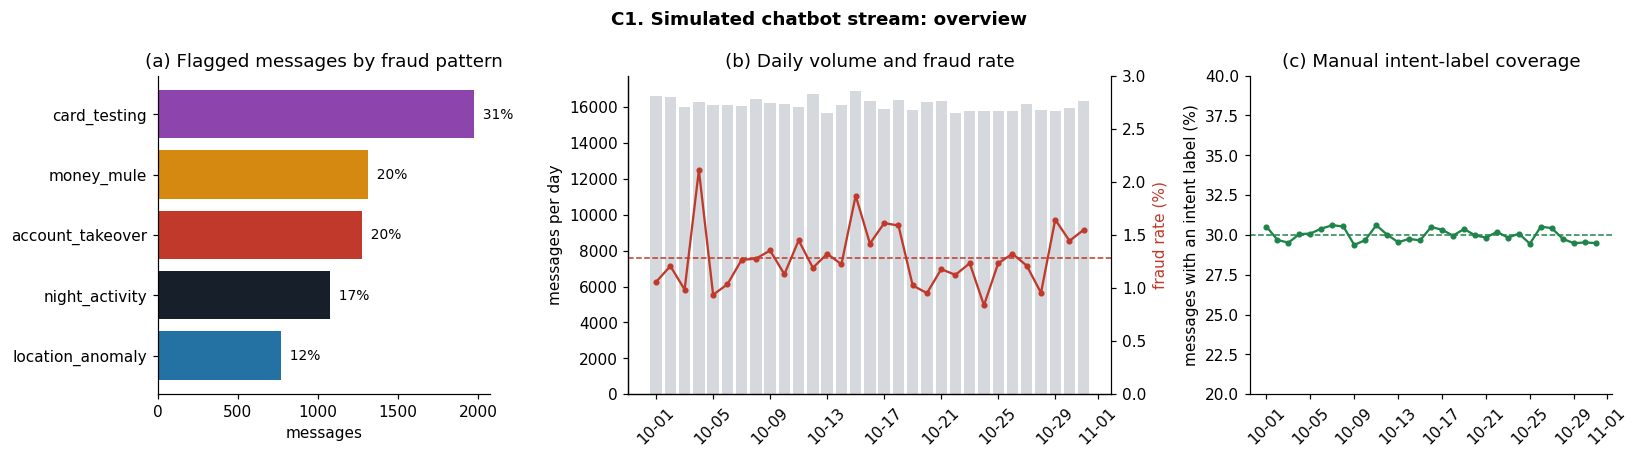

fraud users: 800 (8.0%)
daily fraud rate: mean 1.28%, min 0.84%, max 2.11%


In [5]:
daily = timed("C1 daily", lambda: (
    msgs.groupBy(F.to_date("received_ts").alias("day")).agg(
        F.count("*").alias("messages"),
        F.avg(F.col("is_fraud").cast("int")).alias("fraud_rate"),
        F.avg(F.col("label").isNotNull().cast("int")).alias("label_coverage"),
    ).orderBy("day").toPandas()
))
daily["day"] = pd.to_datetime(daily["day"])
daily.to_csv(OUT_DIR / "C1_daily.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.1, 1.6, 1.2]})

# (a) share of fraud messages by pattern
p = persona[persona["persona"] != "normal"].sort_values("fraud_messages")
axes[0].barh(p["persona"], p["fraud_messages"], color=[COLORS[x] for x in p["persona"]])
for y, (n, s) in enumerate(zip(p["fraud_messages"], p["share_of_fraud_messages"])):
    axes[0].text(n, y, f"  {s:.0%}", va="center", fontsize=9)
axes[0].set_title("(a) Flagged messages by fraud pattern")
axes[0].set_xlabel("messages")

# (b) daily volume and fraud rate
ax = axes[1]
ax.bar(daily["day"], daily["messages"], color="#d5d8dc", width=0.8, label="messages")
ax.set_ylabel("messages per day")
ax2 = ax.twinx()
ax2.plot(daily["day"], daily["fraud_rate"] * 100, color=COLORS["account_takeover"], marker="o", ms=3, label="fraud rate")
ax2.axhline(daily["fraud_rate"].mean() * 100, color=COLORS["account_takeover"], ls="--", lw=1)
ax2.set_ylabel("fraud rate (%)", color=COLORS["account_takeover"])
ax2.set_ylim(0, max(3, daily["fraud_rate"].max() * 130))
ax2.spines["right"].set_visible(True)
ax.set_title("(b) Daily volume and fraud rate")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax.tick_params(axis="x", rotation=45)

# (c) manual label coverage per day
axes[2].plot(daily["day"], daily["label_coverage"] * 100, color="#1e8449", marker="o", ms=3)
axes[2].axhline(30, color="#1e8449", ls="--", lw=1)
axes[2].set_ylim(20, 40)
axes[2].set_ylabel("messages with an intent label (%)")
axes[2].set_title("(c) Manual intent-label coverage")
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
axes[2].tick_params(axis="x", rotation=45)

fig.suptitle("C1. Simulated chatbot stream: overview", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "C1_overview.png", bbox_inches="tight")
plt.show()

print(f"fraud users: {persona.loc[persona.persona != 'normal', 'users'].sum()} "
      f"({persona.loc[persona.persona != 'normal', 'share_of_users'].sum():.1%})")
print(f"daily fraud rate: mean {daily.fraud_rate.mean():.2%}, min {daily.fraud_rate.min():.2%}, max {daily.fraud_rate.max():.2%}")

About 8% of users follow a fraud pattern, but only about 1.3% of messages are flagged, because each fraud user sends mostly ordinary background messages and the flagged burst is short. This is the class imbalance a real fraud team faces: alerts are rare, so accuracy is a poor metric and recall and precision on the fraud class matter more. Card testing has fewer users than account takeover (174 vs. 215) but contributes the largest share of flagged messages (31%), because each card-testing burst averages about 11 messages, which matches how card-testing attacks probe many authorizations at once. The daily fraud rate moves between about 0.8% and 2.0% with no upward or downward trend; the day-to-day swings come from having only around 25 fraud bursts per day. Manual label coverage stays close to the configured 30%, so the stream has no date-based pattern a model could exploit.

One simulation artifact is visible in the persona table: normal users send about 52 messages over the month, while fraud users send only 20 to 26, because the simulator gives fraud users a smaller background of ordinary sessions. A model could learn “fewer messages means fraud” from this alone, so per-user message counts should be excluded from the fraud model or the simulator should match background volumes across personas.

## C2. When do people message? Hour of day × day of week

Each cell is the share of that group’s messages sent in that hour and weekday. Because a one-month window does not contain every weekday equally often (October 2026 has five Thursdays, Fridays and Saturdays but four of each other day), counts are first divided by the number of calendar days for each weekday, so each cell describes an average day. Shares rather than counts make the normal and fraud panels comparable even though fraud is only about 1.3% of traffic. Times are the user’s local clock.

C2 heatmap: 1.1 s


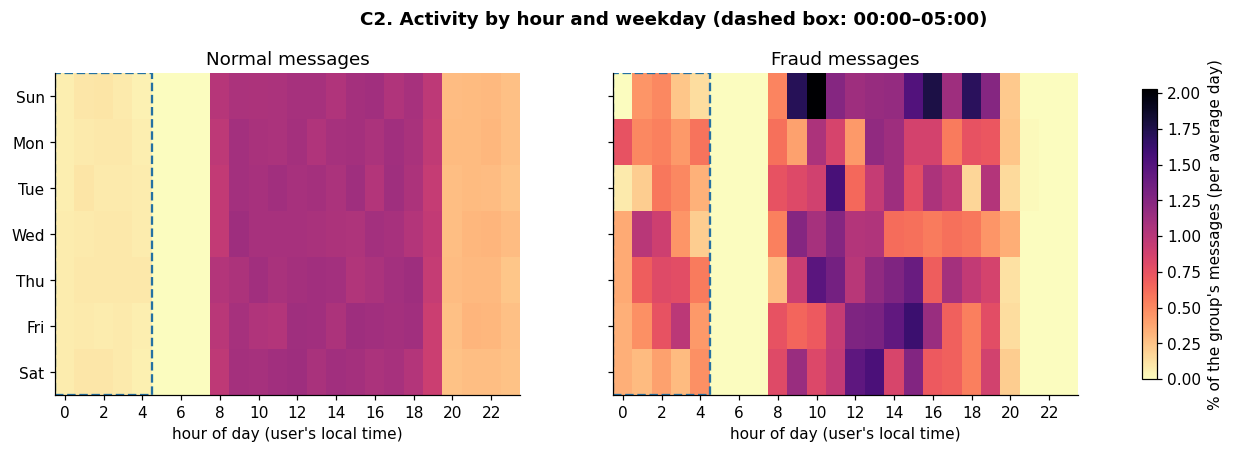

share of messages between 00:00 and 05:00:
kind
fraud     16.7%
normal     2.9%
dtype: object


In [6]:
heat = timed("C2 heatmap", lambda: (
    msgs.withColumn("kind", F.when(F.col("is_fraud"), "fraud").otherwise("normal"))
    .groupBy("kind", F.hour("received_ts").alias("hour"), F.dayofweek("received_ts").alias("dow"))
    .count().toPandas()
))
# A one-month window does not contain every weekday equally often (October 2026 has five Thursdays,
# Fridays and Saturdays but four of every other day). Divide by the number of calendar days per weekday,
# so each cell is an average day, then turn it into a share of the group's activity.
days_per_dow = (
    msgs.select(F.to_date("received_ts").alias("d")).distinct()
    .groupBy(F.dayofweek("d").alias("dow")).count().withColumnRenamed("count", "n_days").toPandas()
)
heat = heat.merge(days_per_dow, on="dow")
heat["per_day"] = heat["count"] / heat["n_days"]
heat["share"] = heat["per_day"] / heat.groupby("kind")["per_day"].transform("sum")
heat.to_csv(OUT_DIR / "C2_hour_dow.csv", index=False)

DOW = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]   # Spark dayofweek: 1 = Sunday
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
vmax = heat["share"].max()
for ax, kind in zip(axes, ["normal", "fraud"]):
    grid = (heat[heat.kind == kind].pivot(index="dow", columns="hour", values="share")
            .reindex(index=range(1, 8), columns=range(24)).fillna(0))
    im = ax.imshow(grid * 100, aspect="auto", cmap="magma_r", vmin=0, vmax=vmax * 100)
    ax.set_yticks(range(7), DOW)
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("hour of day (user's local time)")
    ax.set_title(f"{kind.capitalize()} messages")
    ax.axvspan(-0.5, 4.5, fill=False, ec="#2471a3", lw=1.5, ls="--")
fig.colorbar(im, ax=axes, label="% of the group's messages (per average day)", shrink=0.9)
fig.suptitle("C2. Activity by hour and weekday (dashed box: 00:00–05:00)", fontweight="bold", y=1.03)
fig.savefig(FIG_DIR / "C2_hour_weekday.png", bbox_inches="tight")
plt.show()

hourly = heat.groupby(["kind", "hour"])["share"].sum().unstack(0)
night = hourly.loc[0:4].sum()
print("share of messages between 00:00 and 05:00:")
print((night * 100).round(1).astype(str) + "%")

C2 hourly by pattern: 0.74 s


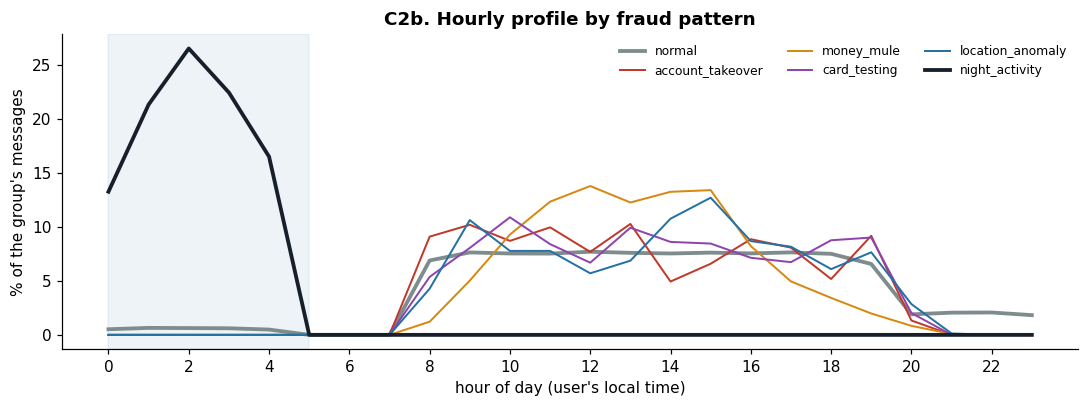

In [7]:
# Hourly profile per fraud pattern, to show that only night_activity drives the night peak
hp = timed("C2 hourly by pattern", lambda: (
    msgs.groupBy("group", F.hour("received_ts").alias("hour")).count().toPandas()
))
hp["share"] = hp["count"] / hp.groupby("group")["count"].transform("sum")
hp = hp.pivot(index="hour", columns="group", values="share").reindex(range(24)).fillna(0)

fig, ax = plt.subplots(figsize=(10, 3.8))
for g in ["normal"] + PATTERNS:
    ax.plot(hp.index, hp[g] * 100, label=g, color=COLORS[g],
            lw=2.5 if g in ("normal", "night_activity") else 1.3)
ax.axvspan(0, 5, color="#2471a3", alpha=0.08)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of day (user's local time)")
ax.set_ylabel("% of the group's messages")
ax.legend(ncol=3, fontsize=8, frameon=False)
ax.set_title("C2b. Hourly profile by fraud pattern", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "C2b_hourly_by_pattern.png", bbox_inches="tight")
plt.show()

Normal traffic follows a working-day rhythm (08:00–20:00) with a smaller evening tail (20:00–24:00); about 3.1% of normal messages fall between 00:00 and 05:00. For flagged fraud the share is 16.7%, and C2b shows that this night block comes entirely from the night activity pattern: attackers operate while the legitimate customer is asleep and less likely to notice alerts. The other four patterns sit in normal daytime hours, so time of day alone cannot catch most fraud, and because genuine customers also message after midnight, a simple “after midnight” rule would raise false alarms. Money-mule activity is concentrated around midday because the incoming payments start in the morning and the outgoing burst follows within hours.

The fraud heatmap looks patchy because it is built from only about 6,400 flagged messages spread over 168 cells (fewer than 40 per cell on average), so a single card-testing burst can darken one cell. Individual dark cells, such as Sunday at 10:00, reflect a few bursts landing there by chance and should not be read as a weekday pattern.

Three limits of the simulation are visible here and should be stated, not read as findings: there is no weekday effect (the normal rows look alike once each weekday is counted the same number of times), no messages fall between 05:00 and 08:00, and flagged fraud almost never appears after 20:00 and never after 21:00. The last point is a shortcut a model could learn, so a next version of the simulator should let daytime fraud patterns extend into the evening.

## C3. How fast? Time between consecutive messages of the same user

For every message we compute the gap to the same user’s previous message with a Spark window function (lag over user_id, ordered by time). Each gap is grouped by the current message: within a session means the previous message is in the same session, so for fraud groups these are gaps inside the flagged burst; between sessions means the current message opens a new visit, so for fraud groups this is the quiet period before the burst begins. This per-user, time-ordered window is the step that grows with the data: on the full 50-million-message stream it requires shuffling every user’s history onto one executor, which is why it runs in Spark rather than pandas.

In [8]:
w = Window.partitionBy("user_id").orderBy("received_ts", "message_id")
gaps = (
    msgs.select("user_id", "session_id", "message_id", "received_ts", "group")
    .withColumn("prev_ts", F.lag("received_ts").over(w))
    .withColumn("prev_session", F.lag("session_id").over(w))
    .where(F.col("prev_ts").isNotNull())
    .withColumn("gap_s", F.col("received_ts").cast("long") - F.col("prev_ts").cast("long"))
    .withColumn("scope", F.when(F.col("session_id") == F.col("prev_session"), "within_session").otherwise("between_sessions"))
)

# Summary statistics are computed in Spark; only quantiles come back to the driver
gap_summary = timed("C3 gap quantiles", lambda: (
    gaps.groupBy("scope", "group").agg(
        F.count("*").alias("n"),
        F.percentile_approx("gap_s", [0.1, 0.5, 0.9], 1000).alias("q"),
    ).toPandas()
))
gap_summary[["p10_s", "median_s", "p90_s"]] = pd.DataFrame(gap_summary["q"].tolist(), index=gap_summary.index)
gap_summary = gap_summary.drop(columns="q").sort_values(["scope", "median_s"])
gap_summary.to_csv(OUT_DIR / "C3_gap_quantiles.csv", index=False)
gap_summary

C3 gap quantiles: 3.28 s


,scope,group,n,p10_s,median_s,p90_s
1,between_sessions,location_anomaly,143,60360,104421,361004
4,between_sessions,normal,136301,13255,104999,375544
6,between_sessions,card_testing,160,16625,121766,433236
9,between_sessions,night_activity,110,36269,132376,576190
10,between_sessions,money_mule,136,23248,158913,445371
5,between_sessions,account_takeover,206,12283,159422,505092
2,within_session,card_testing,1802,11,67,227
11,within_session,normal,347327,17,115,431
7,within_session,account_takeover,1061,24,144,511
8,within_session,location_anomaly,629,45,305,1186


C3 gap histogram: 1.44 s


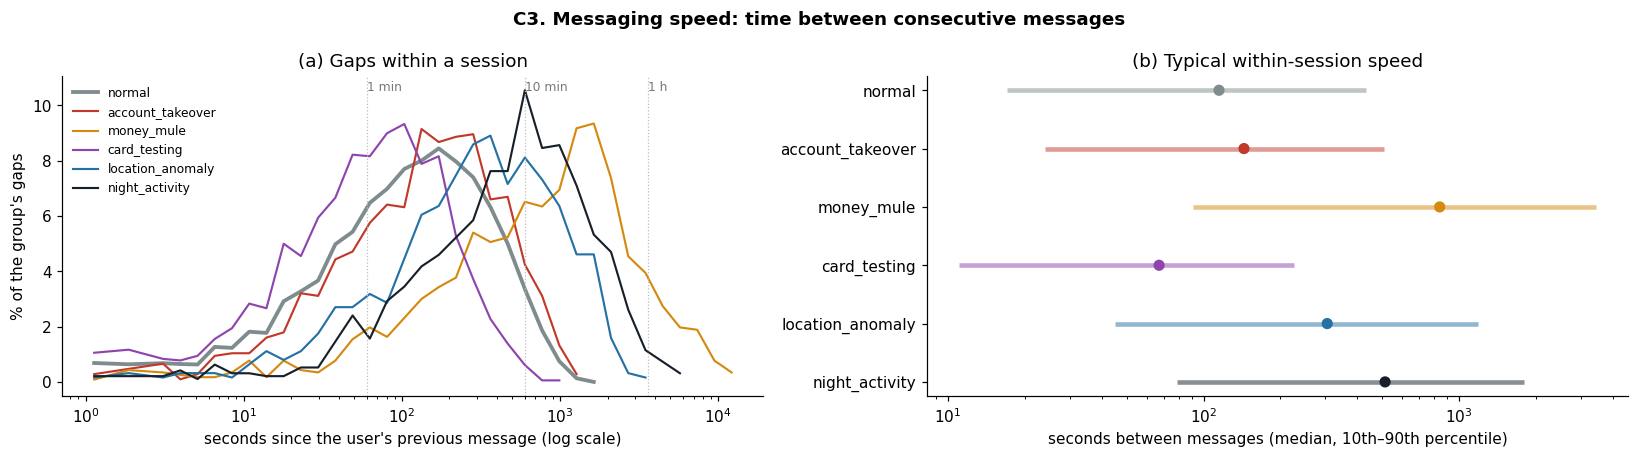

In [9]:
# Log-binned histogram computed in Spark, so the full set of gaps never leaves the cluster
edges = np.logspace(0, np.log10(31 * 24 * 3600), 60)          # 1 second to 31 days
bucket_expr = F.floor(F.log10(F.greatest(F.col("gap_s"), F.lit(1))) / np.log10(edges[1] / edges[0]))
hist = timed("C3 gap histogram", lambda: (
    gaps.where(F.col("scope") == "within_session")
    .groupBy("group", bucket_expr.alias("b")).count().toPandas()
))
hist["density"] = hist["count"] / hist.groupby("group")["count"].transform("sum")
step = np.log10(edges[1] / edges[0])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
ax = axes[0]
for g in ["normal"] + PATTERNS:
    h = hist[hist.group == g].sort_values("b")
    ax.plot(10 ** ((h["b"] + 0.5) * step), h["density"] * 100, label=g, color=COLORS[g],
            lw=2.5 if g == "normal" else 1.4)
for x, lab in [(60, "1 min"), (600, "10 min"), (3600, "1 h")]:
    ax.axvline(x, color="#bbb", lw=0.8, ls=":")
    ax.text(x, ax.get_ylim()[1] * 0.95, lab, fontsize=8, color="#777", ha="left")
ax.set_xscale("log")
ax.set_xlabel("seconds since the user's previous message (log scale)")
ax.set_ylabel("% of the group's gaps")
ax.set_title("(a) Gaps within a session")
ax.legend(fontsize=8, frameon=False)

# (b) median gap with the 10th-90th percentile range
s = gap_summary[gap_summary.scope == "within_session"].set_index("group").reindex(["normal"] + PATTERNS)
y = np.arange(len(s))
axes[1].hlines(y, s["p10_s"], s["p90_s"], color=[COLORS[g] for g in s.index], lw=3, alpha=0.5)
axes[1].scatter(s["median_s"], y, color=[COLORS[g] for g in s.index], zorder=3, s=40)
axes[1].set_yticks(y, s.index)
axes[1].set_xscale("log")
axes[1].set_xlabel("seconds between messages (median, 10th–90th percentile)")
axes[1].set_title("(b) Typical within-session speed")
axes[1].invert_yaxis()

fig.suptitle("C3. Messaging speed: time between consecutive messages", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "C3_message_gaps.png", bbox_inches="tight")
plt.show()

Speed is a weaker signal than we expected. Inside an ordinary session customers wait a median of about two minutes (115 seconds) between messages. Only card testing is clearly faster, with a median of about one minute (67 seconds) and one gap in ten under 11 seconds, which matches how card testers fire repeated authorization attempts in quick succession. Account takeover is almost indistinguishable from an ordinary session by gap alone (median 144 seconds, slightly slower than normal), so the takeover signal has to come from the order of intents (reset credential → change details → move money, part D) rather than from speed. Location anomaly (about 5 minutes), night activity (about 8.5 minutes) and money mule (about 14 minutes) are actually slower than ordinary sessions, because their bursts are spread over one to several hours.

Between sessions, normal users return after a median of about 28 hours, while the quiet period before a fraud burst lasts 2 to 4 days. This does not reflect fraud behaviour: it is the same simulation artifact noted in C1, where fraud users receive fewer background sessions than normal users, so their visits are more widely spaced. Features built on time since the previous visit should therefore not be used in the fraud model until the simulator matches background volumes across personas.

The lesson for modelling is that a per-message feature such as “seconds since the last message” separates only one pattern. Session-level features (how many messages, over how long, and in what order) carry more of the signal, which C4 shows.

## C4. Session size and duration

A session is one visit to the chatbot (`session_id`). We aggregate each session's message count and duration in
Spark, then compare ordinary sessions with flagged fraud bursts.

In [10]:
sessions = timed("C4 sessions", lambda: (
    msgs.groupBy("session_id").agg(
        F.first("group").alias("group"),
        F.count("*").alias("n_messages"),
        ((F.max("received_ts").cast("long") - F.min("received_ts").cast("long")) / 60).alias("duration_min"),
        F.countDistinct("city").alias("n_cities"),
    ).toPandas()
))
sessions.to_csv(OUT_DIR / "C4_sessions.csv.gz", index=False, compression="gzip")
sess_summary = sessions.groupby("group").agg(
    sessions=("session_id", "count"),
    median_messages=("n_messages", "median"),
    max_messages=("n_messages", "max"),
    median_minutes=("duration_min", "median"),
    p90_minutes=("duration_min", lambda x: x.quantile(0.9)),
).round(1).reindex(["normal"] + PATTERNS)
sess_summary.to_csv(OUT_DIR / "C4_session_summary.csv")
sess_summary

C4 sessions: 3.14 s


,sessions,median_messages,max_messages,median_minutes,p90_minutes
group,,,,,
normal,146256,3.0,5,6.0,14.8
account_takeover,215,6.0,8,16.5,29.0
money_mule,147,9.0,12,164.1,305.3
card_testing,174,11.0,15,17.0,24.4
location_anomaly,143,5.0,8,32.8,61.8
night_activity,121,9.0,12,99.3,163.1


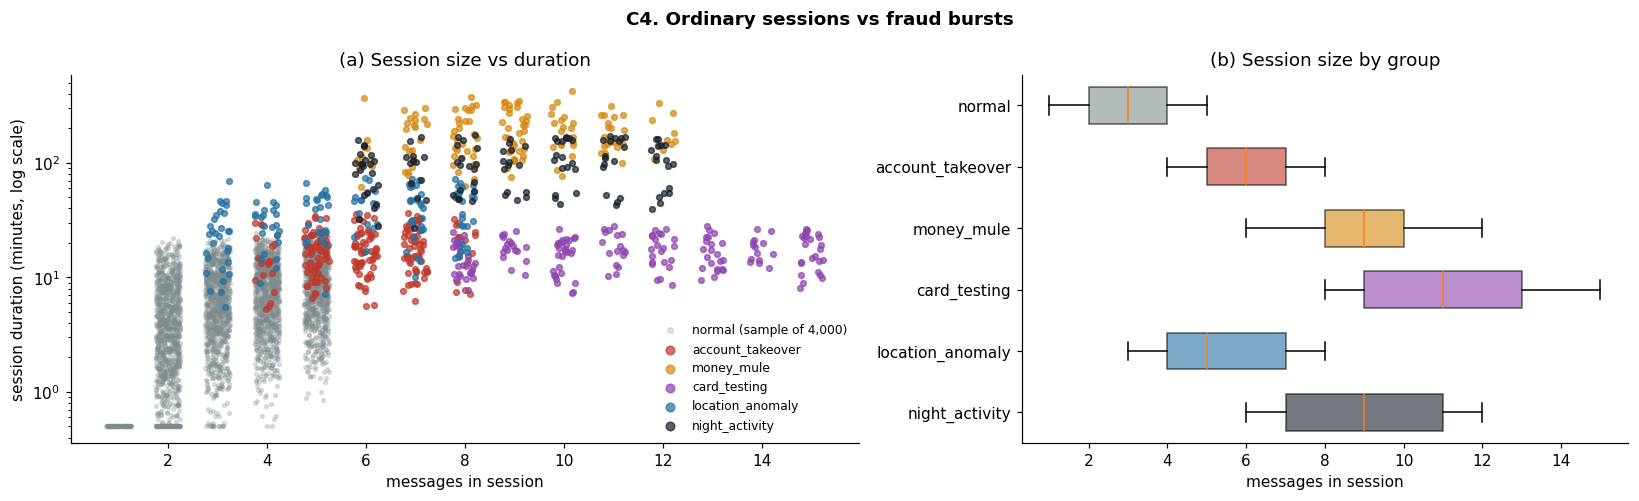

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})

# (a) size vs duration; normal sessions are sampled so fraud bursts stay visible
ax = axes[0]
rng = np.random.default_rng(7)
normal = sessions[sessions.group == "normal"]
normal = normal.sample(min(len(normal), 4000), random_state=7)
jit = lambda n: rng.uniform(-0.25, 0.25, n)
ax.scatter(normal["n_messages"] + jit(len(normal)), normal["duration_min"].clip(lower=0.5),
           s=6, alpha=0.25, color=COLORS["normal"], label="normal (sample of 4,000)")
for g in PATTERNS:
    d = sessions[sessions.group == g]
    ax.scatter(d["n_messages"] + jit(len(d)), d["duration_min"].clip(lower=0.5), s=14, alpha=0.7,
               color=COLORS[g], label=g)
ax.set_yscale("log")
ax.set_xlabel("messages in session")
ax.set_ylabel("session duration (minutes, log scale)")
ax.set_title("(a) Session size vs duration")
ax.legend(fontsize=8, frameon=False, markerscale=1.5)

# (b) distribution of session size by group
ax = axes[1]
order = ["normal"] + PATTERNS
data = [sessions.loc[sessions.group == g, "n_messages"] for g in order]
bp = ax.boxplot(data, vert=False, patch_artist=True, showfliers=False, widths=0.6)
for patch, g in zip(bp["boxes"], order):
    patch.set_facecolor(COLORS[g]); patch.set_alpha(0.6)
ax.set_yticks(range(1, len(order) + 1), order)
ax.invert_yaxis()
ax.set_xlabel("messages in session")
ax.set_title("(b) Session size by group")

fig.suptitle("C4. Ordinary sessions vs fraud bursts", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "C4_sessions.png", bbox_inches="tight")
plt.show()

**Interpretation (draft).**
Ordinary sessions are short: 2–5 messages over a few minutes, one question and a follow-up. Fraud bursts are larger
and sit in a different region of the size–duration plane: card testing packs 8–15 messages into under half an hour,
night activity runs 6–12 messages over one to three hours, and money-mule sessions stretch over several hours because
incoming payments arrive before the fast outflow. No single threshold separates everything (account-takeover bursts are
only a few messages longer than an ordinary session), which is why the fraud model will combine session size, speed,
time of day and intent order rather than rely on one rule.

## Summary for the progress report

1. Fraud is rare at the message level (about 1.3%) even though about 8% of users follow a fraud pattern, so evaluation must focus on fraud-class recall and precision rather than accuracy.
2. Time of day isolates only one pattern (night activity), and genuine customers also message at night.
3. Message-to-message speed isolates only card testing; account takeover moves at a normal customer's pace.
4. Session size and duration (C4) separate every pattern from ordinary 2–5 message sessions, but no single threshold separates them all from each other.
5. None of these behavioral signals is visible in a single message's text, which supports a fraud model that combines text with session-level behavior.

All figures validate the simulation design; they are not claims about real-world fraud.

In [12]:
# Spark job timings, reused in the Spark cluster 1-pager (compare local vs cluster)
pd.Series(timings, name="seconds").to_frame()

,seconds
C1 overview,8.16
C1 persona table,0.73
C1 daily,1.19
C2 heatmap,1.10
C2 hourly by pattern,0.74
C3 gap quantiles,3.28
C3 gap histogram,1.44
C4 sessions,3.14


In [13]:
msgs.unpersist()
spark.stop()